In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [6]:

np.random.seed(42)

n = 300

dates = pd.date_range("2026-01-01", periods=90, freq="D")

df = pd.DataFrame({
    "Date": np.random.choice(dates, n),
    "Visitor_ID": range(1001, 1001 + n),
    "Region": np.random.choice(
        ["South", "North", "East", "West"], n
    ),
    "Marketing_Channel": np.random.choice(
        ["Social Media", "Google", "Email", "Referral"], n
    ),
    "Business_Area": np.random.choice(
        ["Internship", "Training", "IT Services",
         "Digital Services", "Customer Support"], n
    ),
    "Service": np.random.choice(
        ["Python Training", "Data Science",
         "Web Development", "Cloud Services",
         "Internship Program", "Technical Support"], n
    ),
    "Visitors": np.random.randint(50, 1000, n),
    "Applications": np.random.randint(5, 100, n),
    "Inquiries": np.random.randint(5, 150, n),
    "Conversions": np.random.randint(1, 60, n),
    "Revenue": np.random.randint(5000, 100000, n),
    "Customer_Rating": np.random.randint(2, 6, n)
})

df["Date"] = pd.to_datetime(df["Date"])

# Add a few missing values for cleaning practice
df.loc[[5, 20, 45], "Region"] = np.nan
df.loc[[10, 35], "Customer_Rating"] = np.nan

print("Synthetic dataset created successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))


Synthetic dataset created successfully!
Dataset shape: (300, 12)


,Date,Visitor_ID,Region,Marketing_Channel,Business_Area,Service,Visitors,Applications,Inquiries,Conversions,Revenue,Customer_Rating
0,2026-02-21,1001,West,Email,Training,Internship Program,868,9,16,15,75017,2.0
1,2026-01-15,1002,West,Referral,Internship,Web Development,742,15,91,35,68037,5.0
2,2026-03-13,1003,West,Social Media,IT Services,Python Training,341,63,16,28,94818,3.0
3,2026-03-02,1004,East,Social Media,Customer Support,Technical Support,420,92,145,7,11548,4.0
4,2026-01-21,1005,East,Referral,Training,Cloud Services,843,83,29,32,78294,2.0
5,2026-03-24,1006,NaN,Email,Internship,Technical Support,78,42,49,11,28177,4.0
6,2026-03-28,1007,West,Google,IT Services,Data Science,198,76,126,10,29022,2.0
7,2026-03-16,1008,South,Google,IT Services,Data Science,828,9,59,9,10542,3.0
8,2026-03-16,1009,West,Social Media,Internship,Internship Program,345,52,104,14,96012,4.0
9,2026-03-29,1010,West,Email,Customer Support,Web Development,60,94,140,13,65428,5.0


In [7]:

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nDuplicate rows:", df.duplicated().sum())


Dataset dimensions: (300, 12)

Column names:
['Date', 'Visitor_ID', 'Region', 'Marketing_Channel', 'Business_Area', 'Service', 'Visitors', 'Applications', 'Inquiries', 'Conversions', 'Revenue', 'Customer_Rating']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               300 non-null    datetime64[us]
 1   Visitor_ID         300 non-null    int64         
 2   Region             297 non-null    str           
 3   Marketing_Channel  300 non-null    str           
 4   Business_Area      300 non-null    str           
 5   Service            300 non-null    str           
 6   Visitors           300 non-null    int32         
 7   Applications       300 non-null    int32         
 8   Inquiries          300 non-null    int32         
 9   Conversions        300 non-null    int32         


,Missing_Count
Date,0
Visitor_ID,0
Region,3
Marketing_Channel,0
Business_Area,0
Service,0
Visitors,0
Applications,0
Inquiries,0
Conversions,0



Duplicate rows: 0


In [8]:

df = df.drop_duplicates().copy()

df["Region"] = df["Region"].fillna("Unknown")
df["Customer_Rating"] = df["Customer_Rating"].fillna(
    df["Customer_Rating"].median()
)

# Derived business KPIs
df["Conversion_Rate"] = (
    df["Conversions"] / df["Visitors"] * 100
).round(2)

df["Revenue_Per_Inquiry"] = (
    df["Revenue"] / df["Inquiries"]
).round(2)

print("Cleaning and preprocessing completed.")
print("Remaining missing values:", df.isnull().sum().sum())

display(df.head())


Cleaning and preprocessing completed.
Remaining missing values: 0


,Date,Visitor_ID,Region,Marketing_Channel,Business_Area,Service,Visitors,Applications,Inquiries,Conversions,Revenue,Customer_Rating,Conversion_Rate,Revenue_Per_Inquiry
0,2026-02-21,1001,West,Email,Training,Internship Program,868,9,16,15,75017,2.0,1.73,4688.56
1,2026-01-15,1002,West,Referral,Internship,Web Development,742,15,91,35,68037,5.0,4.72,747.66
2,2026-03-13,1003,West,Social Media,IT Services,Python Training,341,63,16,28,94818,3.0,8.21,5926.12
3,2026-03-02,1004,East,Social Media,Customer Support,Technical Support,420,92,145,7,11548,4.0,1.67,79.64
4,2026-01-21,1005,East,Referral,Training,Cloud Services,843,83,29,32,78294,2.0,3.80,2699.79


,Total_Visitors,Total_Applications,Total_Conversions
Marketing_Channel,,,
Social Media,46364,5202,2637
Referral,38133,3881,1746
Email,35308,3468,1854
Google,33498,3215,1812


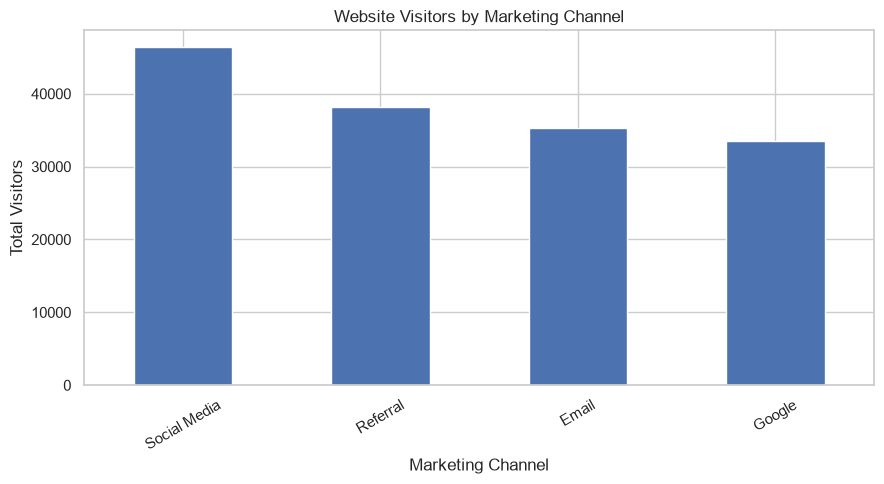

In [9]:

channel_analysis = df.groupby(
    "Marketing_Channel"
).agg(
    Total_Visitors=("Visitors", "sum"),
    Total_Applications=("Applications", "sum"),
    Total_Conversions=("Conversions", "sum")
).sort_values("Total_Visitors", ascending=False)

display(channel_analysis)

channel_analysis["Total_Visitors"].plot(
    kind="bar", figsize=(9, 5), title="Website Visitors by Marketing Channel"
)
plt.xlabel("Marketing Channel")
plt.ylabel("Total Visitors")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [10]:

internship_df = df[df["Business_Area"] == "Internship"]

print("Total internship-related visitor records:",
      len(internship_df))

print("Total applications:",
      internship_df["Applications"].sum())

display(
    internship_df.groupby("Region").agg(
        Applications=("Applications", "sum"),
        Visitors=("Visitors", "sum"),
        Conversions=("Conversions", "sum")
    ).sort_values("Applications", ascending=False)
)


Total internship-related visitor records: 67
Total applications: 3637


,Applications,Visitors,Conversions
Region,,,
West,1423,12359,624
North,1027,7468,326
East,632,5823,439
South,513,5375,238
Unknown,42,78,11


,Total_Applications,Total_Inquiries,Total_Revenue,Average_Rating
Service,,,,
Python Training,603,576,732788,3.18
Web Development,522,601,652473,4.00
Data Science,475,929,588290,4.27
Technical Support,565,887,496382,3.10
Internship Program,606,872,462608,3.18
Cloud Services,403,339,429813,3.33


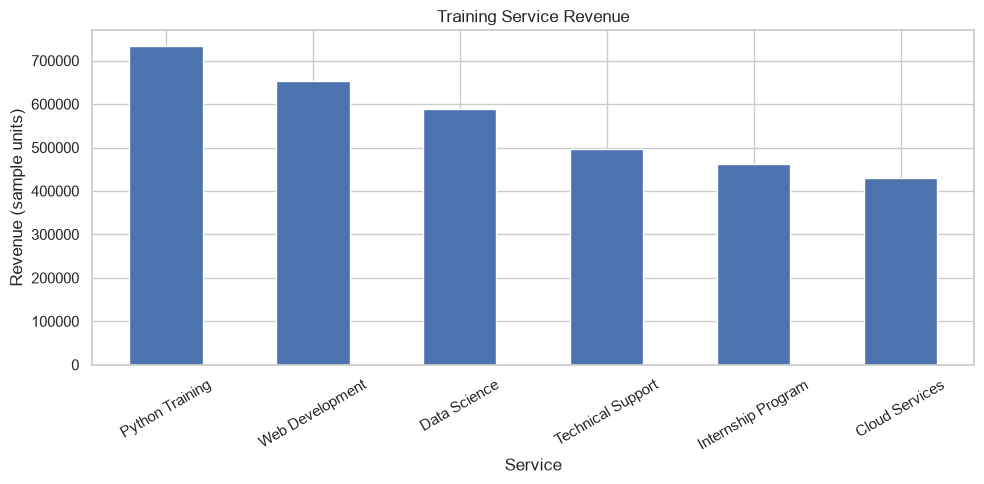

In [11]:

training_df = df[df["Business_Area"] == "Training"]

training_analysis = training_df.groupby("Service").agg(
    Total_Applications=("Applications", "sum"),
    Total_Inquiries=("Inquiries", "sum"),
    Total_Revenue=("Revenue", "sum"),
    Average_Rating=("Customer_Rating", "mean")
).sort_values("Total_Revenue", ascending=False)

display(training_analysis.round(2))

training_analysis["Total_Revenue"].plot(
    kind="bar", figsize=(10, 5),
    title="Training Service Revenue"
)
plt.ylabel("Revenue (sample units)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [12]:

service_analysis = df[
    df["Business_Area"].isin(["IT Services", "Digital Services"])
]

service_summary = service_analysis.groupby(
    ["Business_Area", "Service"]
).agg(
    Total_Inquiries=("Inquiries", "sum"),
    Total_Revenue=("Revenue", "sum")
).sort_values("Total_Inquiries", ascending=False)

display(service_summary)


Total_Inquiries  Total_Revenue
Business_Area    Service                                           
IT Services      Internship Program             1129         827321
                 Technical Support              1078         543209
Digital Services Technical Support              1004         714502
IT Services      Data Science                    842         265972
                 Python Training                 651         761284
Digital Services Web Development                 575         450829
                 Data Science                    563         621284
IT Services      Web Development                 510         370101
Digital Services Python Training                 465         348163
                 Cloud Services                  458         237321
IT Services      Cloud Services                  442         359545
Digital Services Internship Program              347         279204

,Total_Inquiries,Average_Rating,Total_Revenue
Business_Area,,,
Internship,5414,3.70,3504820
Customer Support,5132,3.61,3174686
IT Services,4652,3.38,3127432
Training,4204,3.53,3362354
Digital Services,3412,3.31,2651303


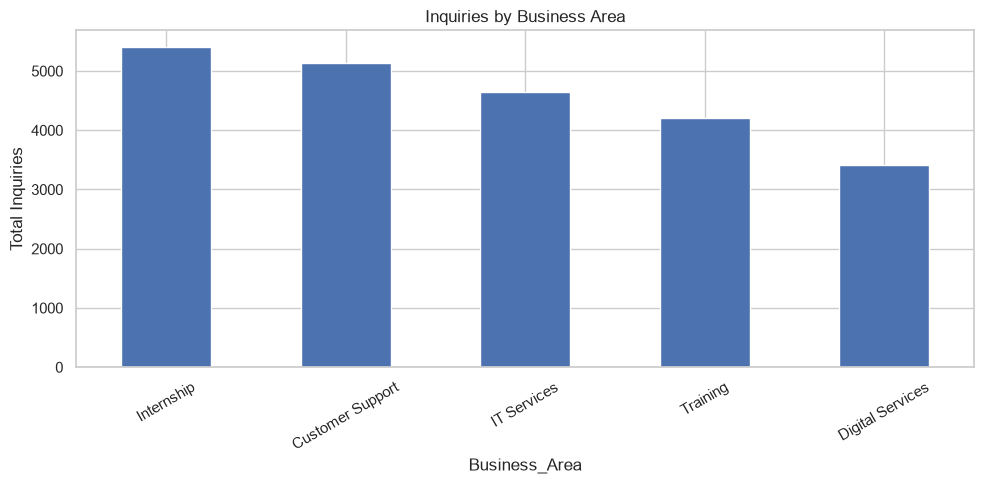

In [13]:

customer_analysis = df.groupby("Business_Area").agg(
    Total_Inquiries=("Inquiries", "sum"),
    Average_Rating=("Customer_Rating", "mean"),
    Total_Revenue=("Revenue", "sum")
).sort_values("Total_Inquiries", ascending=False)

display(customer_analysis.round(2))

customer_analysis["Total_Inquiries"].plot(
    kind="bar", figsize=(10, 5),
    title="Inquiries by Business Area"
)
plt.ylabel("Total Inquiries")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [14]:

df["Customer_Segment"] = pd.cut(
    df["Revenue"],
    bins=[-1, 25000, 60000, float("inf")],
    labels=["Low Revenue", "Medium Revenue", "High Revenue"]
)

segment_analysis = df.groupby(
    "Customer_Segment", observed=False
).agg(
    Records=("Visitor_ID", "count"),
    Total_Revenue=("Revenue", "sum"),
    Average_Rating=("Customer_Rating", "mean")
)

display(segment_analysis.round(2))


,Records,Total_Revenue,Average_Rating
Customer_Segment,,,
Low Revenue,57,878493,3.67
Medium Revenue,113,4656620,3.42
High Revenue,130,10285482,3.53


========== BUSINESS KPI REPORT ==========
Total Visitors: 153,303
Total Applications: 15,766
Total Inquiries: 22,814
Total Conversions: 8,049
Total Revenue: 15,820,595
Overall Conversion Rate: 5.25%


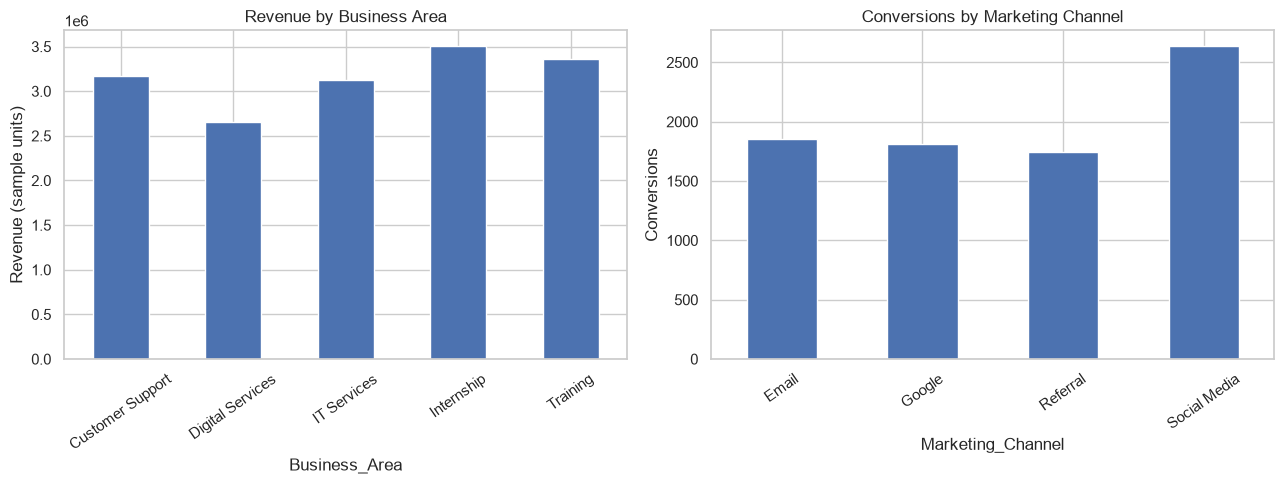

In [15]:

total_visitors = df["Visitors"].sum()
total_applications = df["Applications"].sum()
total_inquiries = df["Inquiries"].sum()
total_conversions = df["Conversions"].sum()
total_revenue = df["Revenue"].sum()

conversion_rate = total_conversions / total_visitors * 100

print("========== BUSINESS KPI REPORT ==========")
print(f"Total Visitors: {total_visitors:,}")
print(f"Total Applications: {total_applications:,}")
print(f"Total Inquiries: {total_inquiries:,}")
print(f"Total Conversions: {total_conversions:,}")
print(f"Total Revenue: {total_revenue:,}")
print(f"Overall Conversion Rate: {conversion_rate:.2f}%")
print("=========================================")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df.groupby("Business_Area")["Revenue"].sum().plot(
    kind="bar", ax=axes[0], title="Revenue by Business Area"
)
df.groupby("Marketing_Channel")["Conversions"].sum().plot(
    kind="bar", ax=axes[1], title="Conversions by Marketing Channel"
)

axes[0].set_ylabel("Revenue (sample units)")
axes[1].set_ylabel("Conversions")
axes[0].tick_params(axis="x", rotation=35)
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


In [17]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Inquiries"]]
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:",
      round(mean_absolute_error(y_test, predictions), 2))
print("R-squared:",
      round(r2_score(y_test, predictions), 3))

example_inquiries = pd.DataFrame({"Inquiries": [50]})
predicted_revenue = model.predict(example_inquiries)[0]

print("Illustrative predicted revenue for 50 inquiries:",
      round(predicted_revenue, 2))


Mean Absolute Error: 21869.47
R-squared: -0.004
Illustrative predicted revenue for 50 inquiries: 53314.73



## Business Insights and Interpretation

1. Website Traffic: The marketing channel with the highest visitor count was ______.

2. Internship Applications: The region with the highest number of applications was ______.

3. Training Performance: The service with the highest simulated revenue was ______.

4. Service Demand: The business area with the highest number of inquiries was ______.

5. Customer Segmentation: The largest revenue segment by record count was ______.

6. Business KPIs: The dataset recorded ______ visitors and ______ total revenue.

7. Predictive Analysis: The model's mean absolute error was ______.

## Recommendations

- Monitor marketing channels that generate visitor traffic and conversions.
- Improve the application process based on application and conversion patterns.
- Review training services with high demand and revenue.
- Track customer inquiries to identify areas needing better support.
- Use predictive results cautiously and validate them with more representative data.

## Conclusion

This project demonstrates how Python and Pandas can be used to clean synthetic business data, calculate KPIs, analyze services and marketing channels, segment records, and build a basic predictive model.


In [20]:

print("BUSINESS INSIGHTS")
print("-----------------")

print("1. Highest website traffic:",
      channel_analysis["Total_Visitors"].idxmax())

print("2. Highest internship applications:",
      internship_df.groupby("Region")["Applications"].sum().idxmax())

print("3. Highest training revenue:",
      training_analysis["Total_Revenue"].idxmax())

print("4. Highest inquiry demand:",
      customer_analysis["Total_Inquiries"].idxmax())

print("5. Largest customer segment:",
      segment_analysis["Records"].idxmax())

print("6. Total visitors:", total_visitors)
print("   Total revenue:", total_revenue)

print("7. Predictive model MAE:",
      round(mean_absolute_error(y_test, predictions), 2))


BUSINESS INSIGHTS
-----------------
1. Highest website traffic: Social Media
2. Highest internship applications: West
3. Highest training revenue: Python Training
4. Highest inquiry demand: Internship
5. Largest customer segment: High Revenue
6. Total visitors: 153303
   Total revenue: 15820595
7. Predictive model MAE: 21869.47
